# Build Matching Dataset for Label Spreading

Loads Grounding DINO predictions (parquet), standard COCO GT, and soft COCO GT,
then performs IoU-based matching to produce a single DataFrame with:
- GDino prediction bbox, score, label, decoder embedding
- Match flag and IoU against soft GT
- Soft label (80-dim) and postprocessed soft label (81-dim, incl. cantsolve)
- COCO GT annotation ID and category for cross-referencing

The output, `data/matched_dataset/coco_val_matched.parquet`, is the input of all
COCO val experiments. It also carries the CLIP crop embeddings
(`clip_embedding`), so `inference/clip_embeddings.py` has to be run on the COCO
val predictions first. Cityscapes, KITTI and Pascal VOC are matched with
`build_matching_dataset.py` instead.

In [1]:
import os
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from pycocotools.coco import COCO

# ── Paths ─────────────────────────────────────────────────────────────────────
PARQUET_PATH = "../inference/predictions/gdino/coco/predictions.parquet"
COCO_GT_PATH = "/home/klees/SoftTeacher/data/coco/annotations/instances_val2017.json"
SOFT_GT_PATH = "../data/soft_datasets/soft_COCO_2017_val.json"
OUTPUT_PATH  = "../data/matched_dataset/coco_val_matched.parquet"

os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)

# ── Matching parameters ───────────────────────────────────────────────────────
IOU_THR       = 0.5    # IoU threshold for a detection to be considered a match
SCORE_THR     = 0.0    # pre-filter predictions below this score (0 = keep all)

N_CLASSES     = 80     # COCO classes
BG_LABEL      = 80     # index used for unmatched / background predictions

/home/klees/miniconda3/envs/label_spreading/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1  Load data

In [2]:
# ── GDino predictions ─────────────────────────────────────────────────────────
df_pred = pd.read_parquet(PARQUET_PATH)
if SCORE_THR > 0:
    df_pred = df_pred[df_pred["score"] >= SCORE_THR].reset_index(drop=True)
print(f"Predictions : {len(df_pred):,} detections across {df_pred['image_id'].nunique():,} images")

# ── Standard COCO GT ──────────────────────────────────────────────────────────
coco_gt = COCO(COCO_GT_PATH)

# category ID → index (0-79) and name
coco_cats       = coco_gt.dataset["categories"]                              # ordered list
coco_id_to_name = {c["id"]: c["name"] for c in coco_cats}
coco_id_to_idx  = {c["id"]: i         for i, c in enumerate(coco_cats)}     # cat ID → 0-79
CAT_IDS_BY_IDX  = np.array([c["id"] for c in coco_cats], dtype=np.int64)   # (80,) idx k -> cat ID,
                                                                            # for projecting GDino's
                                                                            # 91-dim raw per-class probs
                                                                            # (indexed by cat ID) down to
                                                                            # a dense (80,) array in the
                                                                            # same 0-79 order as soft_label

# image ID ↔ file_name
imgid_to_fname  = {img["id"]: img["file_name"] for img in coco_gt.dataset["images"]}
fname_to_imgid  = {v: k for k, v in imgid_to_fname.items()}

# ── Soft COCO GT ──────────────────────────────────────────────────────────────
with open(SOFT_GT_PATH) as f:
    soft_gt = json.load(f)

# soft GT categories (80 COCO classes, same IDs as standard COCO)
soft_cats      = soft_gt["categories"]
soft_id_to_idx = {c["id"]: i for i, c in enumerate(soft_cats)}    # cat ID → 0-79

# key: filename → list of objects; remap to image_id
soft_by_imgid = {}
for fname, objs in soft_gt["objects"].items():
    img_id = fname_to_imgid.get(fname)
    if img_id is not None:
        soft_by_imgid[img_id] = objs

print(f"Soft GT     : {len(soft_by_imgid):,} images with annotations")
print(f"COCO GT     : {len(coco_gt.dataset['images']):,} images")

Predictions : 1,500,000 detections across 5,000 images
loading annotations into memory...


Done (t=0.39s)
creating index...
index created!


Soft GT     : 4,943 images with annotations
COCO GT     : 5,000 images


## 2  IoU matching helpers

In [3]:
def iou_matrix(boxes1, boxes2):
    """(N,4) × (M,4) [x1,y1,x2,y2] → (N,M) IoU matrix."""
    if len(boxes1) == 0 or len(boxes2) == 0:
        return np.zeros((len(boxes1), len(boxes2)))
    x1 = np.maximum(boxes1[:, None, 0], boxes2[None, :, 0])
    y1 = np.maximum(boxes1[:, None, 1], boxes2[None, :, 1])
    x2 = np.minimum(boxes1[:, None, 2], boxes2[None, :, 2])
    y2 = np.minimum(boxes1[:, None, 3], boxes2[None, :, 3])
    inter  = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    areas1 = (boxes1[:, 2] - boxes1[:, 0]) * (boxes1[:, 3] - boxes1[:, 1])
    areas2 = (boxes2[:, 2] - boxes2[:, 0]) * (boxes2[:, 3] - boxes2[:, 1])
    union  = areas1[:, None] + areas2[None, :] - inter
    return inter / np.maximum(union, 1e-6)


def greedy_match(pred_scores, iou_mat, iou_thr):
    """Greedy 1-1 matching sorted by descending score.

    Returns
    -------
    match_iou : (N,) float  – IoU of the matched GT (0 if unmatched)
    match_idx : (N,) int    – index into GT list (-1 if unmatched)
    """
    N, M = iou_mat.shape
    matched_gt = np.zeros(M, dtype=bool)
    match_iou  = np.zeros(N, dtype=np.float32)
    match_idx  = np.full(N, -1, dtype=int)
    for i in np.argsort(pred_scores)[::-1]:
        row = iou_mat[i].copy()
        row[matched_gt] = 0.0
        best = int(row.argmax())
        if row[best] >= iou_thr:
            match_iou[i] = row[best]
            match_idx[i] = best
            matched_gt[best] = True
    return match_iou, match_idx

## 3  Run per-image matching

For each image:
1. Match GDino predictions → **soft GT** objects (IoU ≥ threshold, greedy by score)  
   → `gdino_match`, `gdino_bbox_iou`, `bbox`, `soft_label`, `soft_label_mod`, `score`, `label`

2. Match GDino predictions → **standard COCO GT** annotations (independent greedy matching)  
   → `coco_id`, `category_id`, `category_label`

In [4]:
ZERO_81 = np.zeros(N_CLASSES + 1, dtype=np.float32)   # 81-dim zero vector for unmatched rows

rows = []

for img_id, grp in tqdm(df_pred.groupby("image_id"), desc="Matching images"):

    # ── Prediction arrays ────────────────────────────────────────────────────
    pred_boxes  = np.array(grp["box"].tolist(), dtype=np.float32)   # (N,4) [x1,y1,x2,y2]
    pred_scores = grp["score"].values.astype(np.float32)
    pred_labels = grp["label"].values.astype(np.int32)              # COCO category IDs
    pred_embs   = grp["last_hidden_state"].tolist()                  # list of (256,) arrays
    pred_clip   = grp["clip_embedding"].tolist()                     # list of (512,) CLIP image-crop embeddings
    pred_probs  = np.vstack(grp["probs"].to_numpy()).astype(np.float32)[:, CAT_IDS_BY_IDX]
                                                                      # (N,80) dense per-class sigmoid
                                                                      # confidences, same 0-79 order as
                                                                      # soft_label -- independent per-class
                                                                      # scores (not softmax-normalised),
                                                                      # unlike gdino_score/gdino_label which
                                                                      # only keep the argmax class
    N           = len(pred_boxes)

    # ── Match against soft GT ────────────────────────────────────────────────
    soft_objs      = soft_by_imgid.get(img_id, [])
    soft_match_iou = np.zeros(N, dtype=np.float32)
    soft_match_idx = np.full(N, -1, dtype=int)

    if soft_objs:
        soft_boxes = np.array([o["bbox"] for o in soft_objs], dtype=np.float32)
        iou_mat    = iou_matrix(pred_boxes, soft_boxes)
        soft_match_iou, soft_match_idx = greedy_match(pred_scores, iou_mat, IOU_THR)

    # ── Match against standard COCO GT ───────────────────────────────────────
    coco_anns      = coco_gt.imgToAnns.get(img_id, [])
    coco_match_iou = np.zeros(N, dtype=np.float32)
    coco_match_idx = np.full(N, -1, dtype=int)

    if coco_anns:
        gt_xywh  = np.array([a["bbox"] for a in coco_anns], dtype=np.float32)
        gt_boxes = gt_xywh.copy()
        gt_boxes[:, 2] += gt_boxes[:, 0]
        gt_boxes[:, 3] += gt_boxes[:, 1]
        iou_mat  = iou_matrix(pred_boxes, gt_boxes)
        coco_match_iou, coco_match_idx = greedy_match(pred_scores, iou_mat, IOU_THR)

    # ── Build rows ───────────────────────────────────────────────────────────
    for i in range(N):
        gdino_cat_id   = int(pred_labels[i])
        gdino_cat_name = coco_id_to_name.get(gdino_cat_id, "unknown")

        # Soft GT match
        s_idx = int(soft_match_idx[i])
        if s_idx >= 0:
            sobj      = soft_objs[s_idx]
            bbox_xyxy = sobj["bbox"]
            bbox      = [bbox_xyxy[0], bbox_xyxy[1],
                         bbox_xyxy[2] - bbox_xyxy[0],
                         bbox_xyxy[3] - bbox_xyxy[1]]              # COCO [x,y,w,h]

            # soft_label and postprocessed_soft_label both always have 81 entries:
            # indices 0-79 = 80 COCO classes, index 80 = cantsolve (background)
            # Both already sum to 1.0 — no further normalisation needed.
            soft_label     = np.array(sobj["soft_label"],               dtype=np.float32)  # (81,)
            soft_label_mod = np.array(sobj["postprocessed_soft_label"], dtype=np.float32)  # (81,)
            score          = float(np.max(soft_label))
            label          = int(np.argmax(soft_label))               # 0-79 COCO or 80 cantsolve
        else:
            bbox           = None
            soft_label     = ZERO_81.copy()   # all-zero: no class info for unmatched rows
            soft_label_mod = ZERO_81.copy()
            score          = 0.0
            label          = BG_LABEL         # 80 = cantsolve / background

        # COCO GT match
        c_idx = int(coco_match_idx[i])
        if c_idx >= 0:
            cann            = coco_anns[c_idx]
            coco_id         = float(cann["id"])
            category_id     = float(cann["category_id"])
            category_label  = coco_id_to_name.get(cann["category_id"])
        else:
            coco_id         = None
            category_id     = None
            category_label  = None

        rows.append({
            # ── GDino prediction ─────────────────────────
            "image_id"       : img_id,
            "gdino_pred_id"  : i + 1,
            "gdino_bbox"     : pred_boxes[i].tolist(),
            "gdino_score"    : float(pred_scores[i]),
            "gdino_label"    : gdino_cat_name,
            "gdino_embedding": pred_embs[i],               # (256,) float32
            "clip_embedding" : pred_clip[i],               # (512,) float32, CLIP image-crop embedding
            "gdino_probs"    : pred_probs[i],              # (80,) float32, raw per-class confidences
            # ── Soft GT match ─────────────────────────────
            "gdino_match"    : int(s_idx >= 0),
            "gdino_bbox_iou" : float(soft_match_iou[i]),
            "bbox"           : bbox,                       # [x,y,w,h] COCO format or None
            "score"          : score,
            "soft_label"     : soft_label,                 # (81,) — incl. cantsolve at [80]
            "soft_label_mod" : soft_label_mod,             # (81,) — epsilon-smoothed version
            "label"          : label,                      # 0-79 COCO class or 80 cantsolve/bg
            # ── COCO GT match ─────────────────────────────
            "coco_id"        : coco_id,
            "category_id"    : category_id,
            "category_label" : category_label,
        })

df = pd.DataFrame(rows)
print(f"\nDataset shape : {df.shape}")
print(f"Soft GT match : {df['gdino_match'].sum():,} / {len(df):,}  ({df['gdino_match'].mean():.1%})")
print(f"COCO GT match : {df['coco_id'].notna().sum():,} / {len(df):,}  ({df['coco_id'].notna().mean():.1%})")

Matching images:   0%|          | 0/5000 [00:00<?, ?it/s]

Matching images:   0%|          | 1/5000 [00:00<21:36,  3.85it/s]

Matching images:   1%|          | 45/5000 [00:00<00:31, 157.94it/s]

Matching images:   1%|▏         | 71/5000 [00:00<00:56, 86.82it/s] 

Matching images:   2%|▏         | 115/5000 [00:00<00:32, 149.12it/s]

...

Matching images:  99%|█████████▊| 4926/5000 [00:16<00:00, 322.07it/s]

Matching images:  99%|█████████▉| 4959/5000 [00:16<00:00, 322.66it/s]

Matching images: 100%|█████████▉| 4992/5000 [00:16<00:00, 314.24it/s]

Matching images: 100%|██████████| 5000/5000 [00:16<00:00, 301.93it/s]


Dataset shape : (1500000, 18)
Soft GT match : 49,478 / 1,500,000  (3.3%)
COCO GT match : 35,254 / 1,500,000  (2.4%)


## 4  Inspect

In [5]:
df.info()
df.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500000 entries, 0 to 1499999
Data columns (total 18 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   image_id         1500000 non-null  int64  
 1   gdino_pred_id    1500000 non-null  int64  
 2   gdino_bbox       1500000 non-null  object 
 3   gdino_score      1500000 non-null  float64
 4   gdino_label      1500000 non-null  object 
 5   gdino_embedding  1500000 non-null  object 
 6   clip_embedding   1500000 non-null  object 
 7   gdino_probs      1500000 non-null  object 
 8   gdino_match      1500000 non-null  int64  
 9   gdino_bbox_iou   1500000 non-null  float64
 10  bbox             49478 non-null    object 
 11  score            1500000 non-null  float64
 12  soft_label       1500000 non-null  object 
 13  soft_label_mod   1500000 non-null  object 
 14  label            1500000 non-null  int64  
 15  coco_id          35254 non-null    float64
 16  category_id      3

,image_id,gdino_pred_id,gdino_bbox,gdino_score,gdino_label,gdino_embedding,clip_embedding,gdino_probs,gdino_match,gdino_bbox_iou,bbox,score,soft_label,soft_label_mod,label,coco_id,category_id,category_label
0,139,1,"[408.9117431640625, 157.22401428222656, 463.61...",0.838827,person,"[0.033581637, -0.051338494, -0.17587015, -0.62...","[-0.047607422, 0.28881836, -0.44433594, 0.1140...","[0.8388273, 0.0009086927, 0.000967988, 0.00164...",1,0.858665,"[412, 156, 56, 138]",1.0,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1e-10, 1e-10, 1e-10, 1e-10, 1e-10, 1e-10...",0,230831.0,1.0,person
1,139,2,"[5.974483489990234, 165.9630126953125, 154.506...",0.805527,tv,"[-0.097776204, -0.034336537, -0.22313482, -0.6...","[-0.19238281, 0.09857178, -0.2614746, 0.257812...","[0.0040303413, 0.0005840553, 0.007838611, 0.00...",1,0.899119,"[3, 163, 153, 104]",1.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1e-10, 1e-10, 1e-10, 1e-10, 1e-10, 1e-10, 1e-...",62,34646.0,72.0,tv
2,139,3,"[361.62567138671875, 219.64443969726562, 415.2...",0.734751,chair,"[0.27267453, 0.0027186526, -0.24311383, -0.516...","[-0.22192383, 0.19042969, 0.021697998, 0.06671...","[0.02537243, 0.0055502066, 0.0050066225, 0.002...",1,0.929909,"[360, 219, 55, 102]",1.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1e-10, 1e-10, 1e-10, 1e-10, 1e-10, 1e-10, 1e-...",56,103487.0,62.0,chair


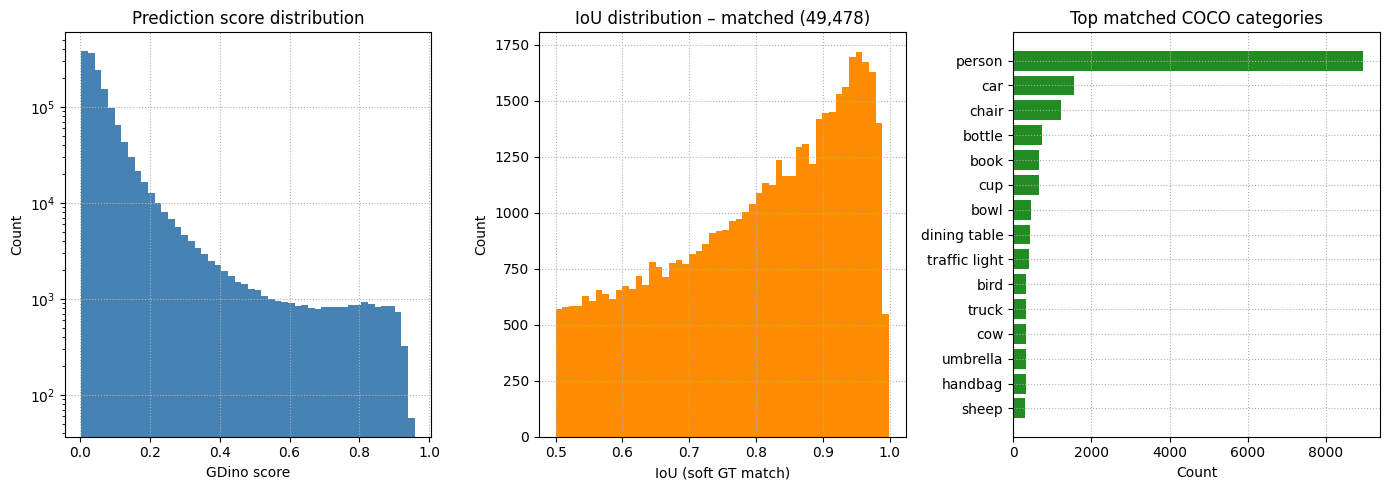

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].hist(df["gdino_score"], bins=50, color="steelblue")
axes[0].set_xlabel("GDino score"); axes[0].set_ylabel("Count")
axes[0].set_title("Prediction score distribution")
axes[0].set_yscale("log"); axes[0].grid(True, ls=":")

matched_iou = df.loc[df["gdino_match"] == 1, "gdino_bbox_iou"]
axes[1].hist(matched_iou, bins=50, color="darkorange")
axes[1].set_xlabel("IoU (soft GT match)"); axes[1].set_ylabel("Count")
axes[1].set_title(f"IoU distribution – matched ({len(matched_iou):,})")
axes[1].grid(True, ls=":")

top_cats = df.loc[df["gdino_match"] == 1, "category_label"].value_counts().head(15)
axes[2].barh(top_cats.index[::-1], top_cats.values[::-1], color="forestgreen")
axes[2].set_xlabel("Count"); axes[2].set_title("Top matched COCO categories")
axes[2].grid(True, ls=":")

plt.tight_layout()
plt.show()

## 5  Save

In [7]:
df.to_parquet(OUTPUT_PATH, engine="pyarrow", compression="snappy", index=False)
print(f"Saved → {OUTPUT_PATH}")
print(f"  Rows    : {len(df):,}")
print(f"  Columns : {df.columns.tolist()}")
print(f"  Size    : {os.path.getsize(OUTPUT_PATH) / 1e6:.1f} MB")

Saved → ../data/matched_dataset/coco_val_matched.parquet
  Rows    : 1,500,000
  Columns : ['image_id', 'gdino_pred_id', 'gdino_bbox', 'gdino_score', 'gdino_label', 'gdino_embedding', 'clip_embedding', 'gdino_probs', 'gdino_match', 'gdino_bbox_iou', 'bbox', 'score', 'soft_label', 'soft_label_mod', 'label', 'coco_id', 'category_id', 'category_label']
  Size    : 3549.2 MB
